<a href="https://colab.research.google.com/github/ramtekeanurag42-max/ramtekeanurag42-max.github.io/blob/main/Student_Score_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

print("Student Score Prediction Using ML")
print("Project started successfully!")

Student Score Prediction Using ML
Project started successfully!


In [ ]:

import pandas as pd

# Create our student dataset
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Marks": [35, 40, 48, 55, 62, 68, 73, 80, 85, 91]
}

df = pd.DataFrame(data)

# Display the dataset
print(df)

   Study_Hours  Marks
0            1     35
1            2     40
2            3     48
3            4     55
4            5     62
5            6     68
6            7     73
7            8     80
8            9     85
9           10     91


In [4]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, r2_score

# Re-create our student dataset to ensure df is defined
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Marks": [35, 40, 48, 55, 62, 68, 73, 80, 85, 91]
}
df = pd.DataFrame(data)

X = df[['Study_Hours']]
y = df['Marks']

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=3, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "KNN Regression": KNeighborsRegressor(n_neighbors=3)
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = []

for name, model in models.items():
    predictions = cross_val_predict(model, X, y, cv=cv)
    mae = mean_absolute_error(y, predictions)
    r2 = r2_score(y, predictions)

    results.append({
        "Model": name,
        "MAE": round(mae, 2),
        "R2 Score": round(r2, 3)
    })

results_df = pd.DataFrame(results)
print(results_df)

best_name = results_df.loc[results_df["MAE"].idxmin(), "Model"]
best_model = models[best_name]
best_model.fit(X, y)

print("\nBest Model:", best_name)

               Model   MAE  R2 Score
0  Linear Regression  0.93     0.996
1      Decision Tree  6.35     0.871
2      Random Forest  4.10     0.932
3     KNN Regression  6.10     0.857

Best Model: Linear Regression


In [ ]:

hours = 7

predicted_marks = model.predict(
    pd.DataFrame({"Study_Hours": [hours]})
)

print("Study Hours:", hours)
print("Predicted Marks:", round(predicted_marks[0], 2))

Study Hours: 7
Predicted Marks: 73.15


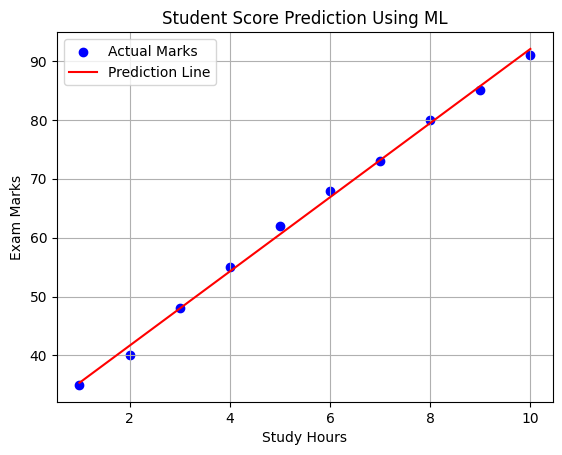

In [ ]:

import matplotlib.pyplot as plt

# Plot actual student data
plt.scatter(X["Study_Hours"], y, color="blue",
            label="Actual Marks")

# Plot the regression line
plt.plot(X["Study_Hours"], model.predict(X),
         color="red", label="Prediction Line")

plt.xlabel("Study Hours")
plt.ylabel("Exam Marks")
plt.title("Student Score Prediction Using ML")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:

from sklearn.metrics import mean_absolute_error, r2_score

# Predict marks for the dataset
predictions = model.predict(X)

# Calculate model performance
mae = mean_absolute_error(y, predictions)
r2 = r2_score(y, predictions)

print("Model Performance")
print("-----------------")
print("Mean Absolute Error:", round(mae, 2))
print("R2 Score:", round(r2, 3))
print("Model training completed successfully!")

Model Performance
-----------------
Mean Absolute Error: 0.79
R2 Score: 0.997
Model training completed successfully!


In [ ]:

hours = float(input("Enter study hours: "))

if hours < 0:
    print("Please enter a positive number.")
else:
    new_data = pd.DataFrame({
        "Study_Hours": [hours]
    })

    predicted_marks = model.predict(new_data)[0]

    # Marks cannot exceed 100
    predicted_marks = max(0, min(100, predicted_marks))

    print("Study Hours:", hours)
    print("Predicted Exam Marks:",
          round(predicted_marks, 2))

Enter study hours: 5.5
Study Hours: 5.5
Predicted Exam Marks: 63.7


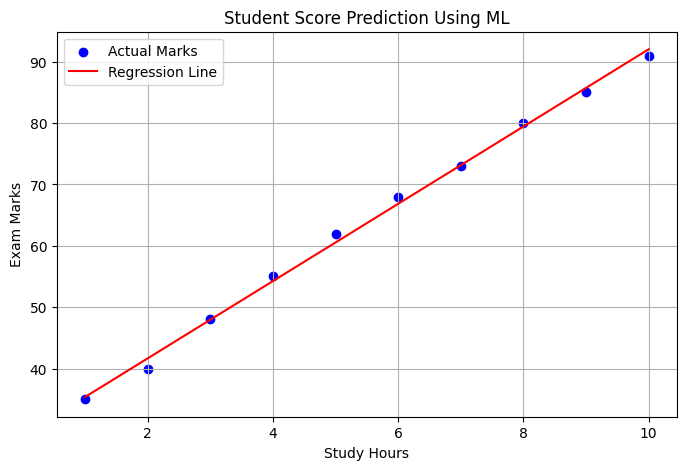

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(X["Study_Hours"], y,
            color="blue", label="Actual Marks")

plt.plot(X["Study_Hours"], model.predict(X),
         color="red", label="Regression Line")

plt.xlabel("Study Hours")
plt.ylabel("Exam Marks")
plt.title("Student Score Prediction Using ML")
plt.legend()
plt.grid(True)
plt.show()

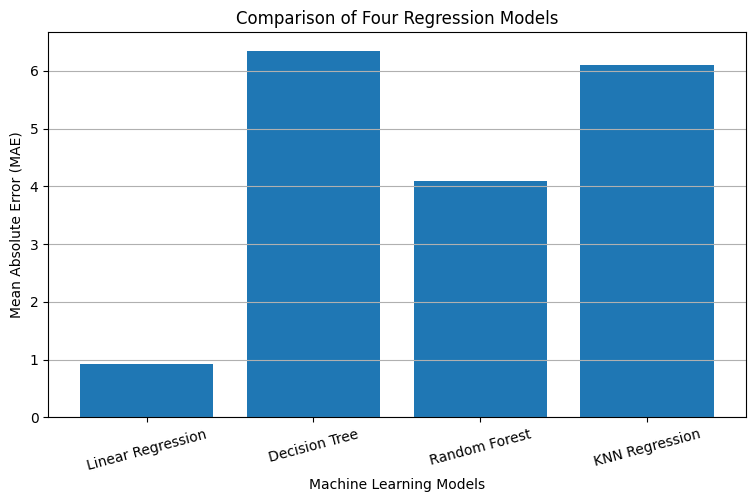

In [5]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["MAE"])

plt.title("Comparison of Four Regression Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean Absolute Error (MAE)")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.show()

In [6]:

hours = float(input("Enter study hours: "))

if hours < 0:
    print("Please enter a positive number.")
else:
    new_data = pd.DataFrame({
        "Study_Hours": [hours]
    })

    predicted_marks = best_model.predict(new_data)[0]
    predicted_marks = max(0, min(100, predicted_marks))

    print("Study Hours:", hours)
    print("Selected Model:", best_name)
    print("Predicted Marks:", round(predicted_marks, 2))

Enter study hours: 7
Study Hours: 7.0
Selected Model: Linear Regression
Predicted Marks: 73.15


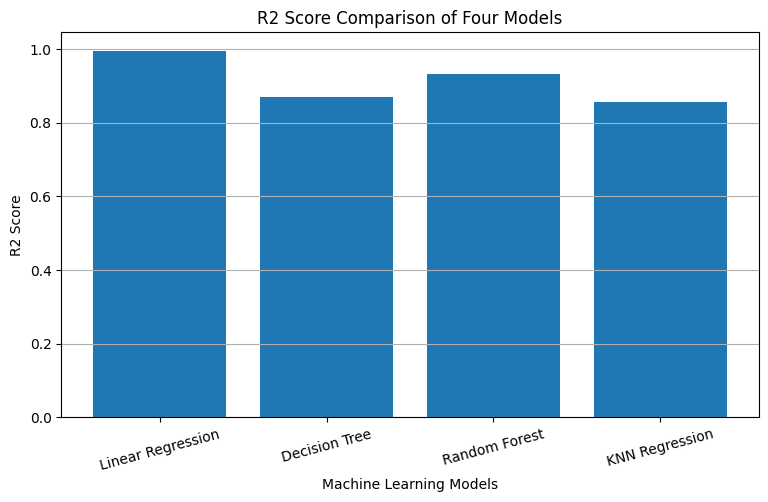

In [7]:

plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["R2 Score"])

plt.title("R2 Score Comparison of Four Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.show()

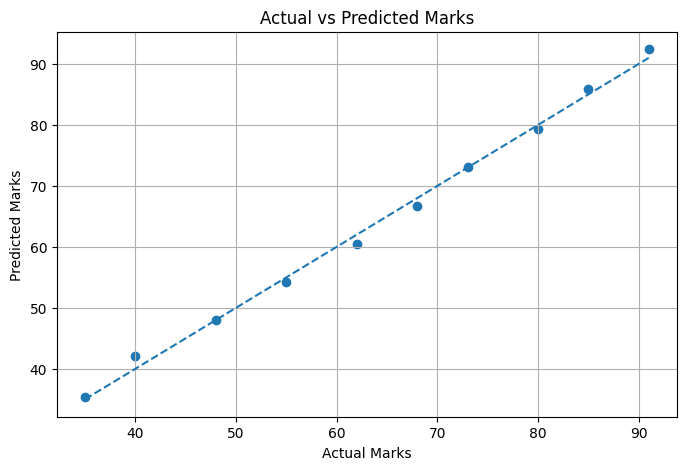

In [8]:

# Cross-validated predictions from the selected model

best_cv_predictions = cross_val_predict(
    models[best_name], X, y, cv=cv
)

plt.figure(figsize=(8, 5))

plt.scatter(y, best_cv_predictions)

plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    linestyle="--"
)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Marks")
plt.grid(True)
plt.show()

In [9]:

# Final Model Comparison

final_results = results_df.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

print("FINAL MODEL PERFORMANCE COMPARISON")
print("-----------------------------------")
print(final_results.to_string(index=False))

print("\nBEST PERFORMING MODEL:", best_name)
print("Selection Criteria: Lowest MAE")

FINAL MODEL PERFORMANCE COMPARISON
-----------------------------------
            Model  MAE  R2 Score
Linear Regression 0.93     0.996
    Random Forest 4.10     0.932
   KNN Regression 6.10     0.857
    Decision Tree 6.35     0.871

BEST PERFORMING MODEL: Linear Regression
Selection Criteria: Lowest MAE


In [10]:

print("===================================")
print(" STUDENT SCORE PREDICTION USING ML")
print("===================================")

print("Dataset Records:", len(df))
print("Input Feature: Study Hours")
print("Target Variable: Marks")
print("Models Compared:", len(models))
print("Selected Model:", best_name)

print("===================================")
print("PROJECT EXECUTION COMPLETED")
print("===================================")

 STUDENT SCORE PREDICTION USING ML
Dataset Records: 10
Input Feature: Study Hours
Target Variable: Marks
Models Compared: 4
Selected Model: Linear Regression
PROJECT EXECUTION COMPLETED
